In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [32]:
df = pd.read_csv("../../course_assignments/homework9/solar_system.csv")
print(df.shape) # 20 rows and 11 columns
print(df.head())
print(df.tail())
print(df['Attribute'].tolist())
print(df.columns.tolist())

(20, 11)
                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  
                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2       95      274   
18             Ring Sy

(24, 11)
                      Attribute Mercury    Venus  Earth    Moon   Mars  \
0                Mass (10^24kg)   0.330     4.87   5.97   0.073  0.642   
1                 Diameter (km)    4879    12104  12756    3475   6792   
2              Density (kg/m^3)    5429     5243   5514    3340   3934   
3               Gravity (m/s^2)     3.7      8.9    9.8     1.6    3.7   
4        Escape Velocity (km/s)     4.3     10.4   11.2     2.4    5.0   
5       Rotation Period (hours)  1407.6  -5832.5   23.9   655.7   24.6   
6         Length of Day (hours)  4222.6   2802.0   24.0   708.7   24.7   
7   Distance from Sun (10^6 km)    57.9    108.2  149.6   0.384  228.0   
8          Perihelion (10^6 km)    46.0    107.5  147.1   0.363  206.7   
9            Aphelion (10^6 km)    69.8    108.9  152.1   0.406  249.3   
10        Orbital Period (days)    88.0    224.7  365.2    27.3  687.0   
11      Orbital Velocity (km/s)    47.4     35.0   29.8     1.0   24.1   
12    Orbital Inclination (de

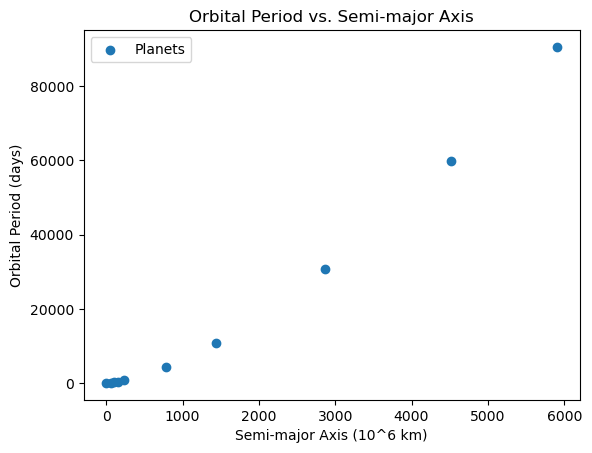

T = 0.20 * a ^ 1.5


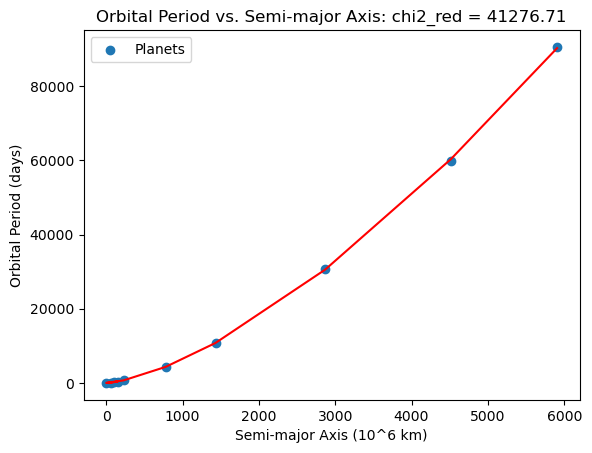

In [36]:

T = df.iloc[10,1:].astype(float)
A = df.iloc[9,1:].astype(float)
P = df.iloc[8,1:].astype(float)

# Perihilion is when the object is closest to the star in its orbit and aphelion is when it is furthest. Oribital period is the time to complete one orbit.

sm_ax = (P + A) / 2
new_row = ["Semi-major axis (10^6 km)"] + ((P + A) / 2).tolist()
df.loc[len(df)] = new_row

print(df.shape) # 21 rows and 11 columns
print(df)

plt.figure()
plt.scatter(sm_ax, T, label="Planets")
plt.xlabel("Semi-major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Orbital Period vs. Semi-major Axis")
plt.legend()
plt.show()

def model(a,m):
    return m * a ** 1.5

popt, pcov = curve_fit(model, sm_ax, T)
m_fit = popt[0]

print(f"T = {m_fit:.2f} * a ^ 1.5")

residuals = T - model(sm_ax, m_fit)
chi2 = np.sum(residuals**2)
dof = len(T) - 1
chi2_reduced = chi2 / dof

plt.figure()
plt.scatter(sm_ax, T, label="Planets")
plt.plot(sm_ax, model(sm_ax, m_fit), color = 'red')
plt.xlabel("Semi-major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title(f"Orbital Period vs. Semi-major Axis: chi2_red = {chi2_reduced:.2f}")
plt.legend()
plt.show()

df.to_csv("kepler.csv", index=False)